# 02 · One-stage anchor-based detector: RetinaNet

**Accelerator: GPU T4 x2** Inputs: competition data, `vd-utils`, output of notebook `00`, output of notebook `01` (for the comparison with Faster R-CNN).

**Protocol:** identical to Faster R-CNN (notebook 01): train folds ≠ 0 / every 10th frame / masked / long side 1344; validate on fold 0 original frames; shared COCO evaluator; 8 epochs, batch 4, SGD with warmup + cosine, AMP, horizontal flip.
Only the learning rate differs: 0.005 instead of 0.01, because the freshly initialised dense classification head of RetinaNet is less stable than the RoI head at high learning rates.

**Model.** torchvision RetinaNet ResNet-50-FPN **v2** (COCO-pretrained; GroupNorm heads, GIoU box loss), new 8-class classification head.
It predicts a class score and a box for each of 9 anchors at every location of P3–P7 (strides 8–128): about 190 k anchors for a 1344×756 frame.

**Runs.** Each tuned run changes one setting of `retina_base`. Version 1 trained the baseline and the k-means anchors; the k-means anchors failed (mAP 0.05),
because k-means matches box *shapes* but ignores where anchors sit: anchors much smaller than their level's stride leave gaps between grid points (coverage table below).
Version 2 therefore tests stride-aware smaller anchors and the box loss.

| run | change vs `retina_base` | motivation |
|---|---|---|
| `retina_base` | torchvision defaults: sizes 32–812 px (3 scales × 3 ratios per level P3–P7), IoU ≥ 0.5 positive / < 0.4 negative, GIoU loss | reference |
| `retina_anchors` | k-means sizes 9–112 px and ratios 0.57 / 1.09 / 2.05 (notebook 00) | k-means IoU 0.82 vs 0.60 for the defaults — **failed**, see coverage table |
| `retina_anchors_x05` | all default anchor sizes × 0.5 (16–406 px), size/stride ratio 2 instead of 4 | the smallest default anchor (32 px) equals the median object; halving keeps every anchor ≥ 2× its stride |
| `retina_ciou` | box loss GIoU → CIoU (**loss modification**) | CIoU adds centre-distance and aspect-ratio terms that keep a useful gradient for tiny, barely-overlapping boxes |

In [1]:
import os, sys, glob, gc, json, time, zipfile, subprocess, traceback
try:
    import pycocotools
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycocotools"], check=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torchvision

def find_utils():
    if os.path.exists("vd_utils.py"):
        return "."
    for depth in range(1, 6):
        hits = glob.glob(os.path.join("/kaggle/input", *["*"] * depth, "vd_utils.py"))
        if hits:
            return os.path.dirname(hits[0])
    raise FileNotFoundError("Add the vd-utils dataset as notebook input")

sys.path.insert(0, find_utils())
import vd_utils as U

print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| GPUs", torch.cuda.device_count())

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | GPUs 2


In [2]:
# --- Configuration: anchors come from the k-means of notebook 00 (training folds only) ----
SEED = 42
VAL_FOLD, STEP = 0, 10
EPOCHS, BATCH, LR, WORKERS = 8, 4, 0.005, 2
KIND = "retinanet"
WORK, RUNS_DIR = "/kaggle/working", "/kaggle/working/runs_tv"

anchors = json.load(open(os.path.join(U.prep_root(), "anchors.json")))
print("k-means anchors:", anchors["retinanet_sizes"], "ratios:", anchors["aspect_ratios_h_over_w"],
      "| mean best IoU:", anchors["mean_iou"])
KMEANS = dict(anchor_sizes=[tuple(s) for s in anchors["retinanet_sizes"]],
              aspect_ratios=tuple(anchors["aspect_ratios_h_over_w"]))

DEFAULT_SIZES = [(x, x * 2 ** (1 / 3), x * 2 ** (2 / 3)) for x in (32, 64, 128, 256, 512)]   # torchvision default
HALF = dict(anchor_sizes=[tuple(round(v / 2, 1) for v in lvl) for lvl in DEFAULT_SIZES])
RUNS = {
    "retina_base":        {},
    "retina_anchors":     KMEANS,
    "retina_anchors_x05": HALF,
    "retina_ciou":        {"bbox_reg_loss": "ciou"},
}
RUNS_TO_TRAIN = ["retina_anchors_x05", "retina_ciou"]   # version 1 trained retina_base + retina_anchors
U.seed_everything(SEED)
os.makedirs(f"{WORK}/results", exist_ok=True)

k-means anchors: [[8.7, 13.2, 16.1], [18.3, 22.0, 24.7], [27.7, 28.4, 32.8], [39.7, 44.1, 45.5], [67.7, 68.1, 112.4]] ratios: [0.57, 1.09, 2.05] | mean best IoU: {'default': 0.601, 'data_driven': 0.821}


In [3]:
# --- Train / validation frames and COCO ground truth (same as notebook 01) -------------
frames, anns = U.load_prep()
train_folds = [f for f in sorted(frames.fold.unique()) if f != VAL_FOLD]
tr = U.select_frames(frames, folds=train_folds, step=STEP)
va = U.select_frames(frames, folds=VAL_FOLD, step=STEP)
train_paths, val_paths = U.train_image_paths(tr), U.orig_image_paths(va)
gt_json, key2id = U.make_coco_gt(va, anns, f"{WORK}/gt_val.json")
val_ids = [key2id[k] for k in va.key]
print(f"train {len(tr)} frames | val {len(va)} frames")

train 2161 frames | val 573 frames


## Anchor coverage on the real grid

For every training box (rescaled to the 1344 px input) the best IoU with any anchor **placed on the feature-map grid** of P3–P7 (strides 8–128).
A box can only become a positive sample if this IoU reaches the positive threshold (0.5), apart from the single best anchor that torchvision always keeps as a low-quality match.

In [4]:
# --- Best anchor IoU per GT box for each anchor configuration (training folds only) ----------
STRIDES = [8, 16, 32, 64, 128]
fit = tr.merge(frames[["key"]], on="key")
b = anns[(anns.iscrowd == 0) & anns.key.isin(fit.key)].merge(fit[["key", "orig_w", "orig_h"]], on="key")
b = b.sample(min(len(b), 50_000), random_state=SEED)
scale = 1344 / b[["orig_w", "orig_h"]].max(axis=1).values                 # torchvision resizes the long side to 1344
boxes = np.c_[b.x * scale, b.y * scale, b.w * scale, b.h * scale]
size = np.sqrt(boxes[:, 2] * boxes[:, 3])
bucket = pd.cut(size, [0, 16, 32, 96, np.inf], labels=["<16", "16-32", "32-96", ">96"])

configs = {"retina_base": (DEFAULT_SIZES, (0.5, 1.0, 2.0)),
           "retina_anchors (k-means)": (KMEANS["anchor_sizes"], KMEANS["aspect_ratios"]),
           "retina_anchors_x05": (HALF["anchor_sizes"], (0.5, 1.0, 2.0))}
rows = {}
for name, (sizes, ratios) in configs.items():
    iou = U.anchor_grid_iou(boxes, STRIDES, sizes, ratios)
    rows[name] = {"mean best IoU": iou.mean(), "share IoU>=0.5": (iou >= 0.5).mean(),
                  **{f"IoU>=0.5 {k}": (iou[bucket == k] >= 0.5).mean() for k in bucket.categories if (bucket == k).any()}}
pd.DataFrame(rows).T.round(3)

,mean best IoU,share IoU>=0.5,IoU>=0.5 <16,IoU>=0.5 16-32,IoU>=0.5 32-96,IoU>=0.5 >96
retina_base,0.623,0.749,0.000,0.611,1.000,0.996
retina_anchors (k-means),0.503,0.500,0.679,0.734,0.277,0.140
retina_anchors_x05,0.665,0.956,0.573,0.990,0.995,0.991


## Training

In [5]:
# --- Train the selected runs, one process per GPU --------------------------------------
cfgs = [dict(name=n, kind=KIND, model_kwargs=RUNS[n], train_paths=train_paths, epochs=EPOCHS, batch=BATCH,
             lr=LR, workers=WORKERS, seed=SEED, out_dir=f"{RUNS_DIR}/{n}") for n in RUNS_TO_TRAIN]
if cfgs:
    U.train_parallel(cfgs)

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth
Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth


100%|██████████| 146M/146M [00:00<00:00, 191MB/s]
100%|██████████| 146M/146M [00:00<00:00, 173MB/s]


retina_anchors_x05 {'epoch': 1, 'classification': 0.5029, 'bbox_regression': 0.3998, 'skipped': 0, 'minutes': 5.2}
retina_ciou {'epoch': 1, 'classification': 0.4356, 'bbox_regression': 0.2638, 'skipped': 0, 'minutes': 5.4}
retina_anchors_x05 {'epoch': 2, 'classification': 0.3114, 'bbox_regression': 0.2854, 'skipped': 0, 'minutes': 10.2}
retina_ciou {'epoch': 2, 'classification': 0.2622, 'bbox_regression': 0.243, 'skipped': 0, 'minutes': 10.6}
retina_anchors_x05 {'epoch': 3, 'classification': 0.2679, 'bbox_regression': 0.2703, 'skipped': 0, 'minutes': 15.3}
retina_ciou {'epoch': 3, 'classification': 0.22, 'bbox_regression': 0.2348, 'skipped': 0, 'minutes': 15.9}
retina_anchors_x05 {'epoch': 4, 'classification': 0.2412, 'bbox_regression': 0.2627, 'skipped': 0, 'minutes': 20.4}
retina_ciou {'epoch': 4, 'classification': 0.1976, 'bbox_regression': 0.2295, 'skipped': 0, 'minutes': 21.1}
retina_anchors_x05 {'epoch': 5, 'classification': 0.2236, 'bbox_regression': 0.2582, 'skipped': 0, 'minut

## Validation results

In [6]:
# --- Evaluate every finished run with the shared COCO evaluator -----------------------
def evaluate(name):
    gc.collect(); torch.cuda.empty_cache()
    model = U.load_detector(KIND, RUNS[name], U.find_run_file(name, "model.pt"))
    dets = []
    for img_id, p in zip(val_ids, val_paths):
        dets += U.to_coco_dets(img_id, *U.detect(model, p))
    m = U.coco_evaluate(gt_json, dets)
    m["FPS"] = round(U.measure_fps(lambda p: U.detect(model, p), val_paths[:70], warmup=10, n=60), 1)
    info = U.find_run_file(name, "info.json")
    m["train_h"] = json.load(open(info))["train_hours"] if info else float("nan")
    return m

results = {}
for name in RUNS:
    if U.find_run_file(name, "model.pt") is None:
        print(f"{name}: not trained yet")
        continue
    try:
        results[name] = evaluate(name)
    except Exception:
        traceback.print_exc()
        continue
    with open(f"{WORK}/results/{name}.json", "w") as f:
        json.dump(results[name], f)

if results:
    res = pd.DataFrame(results).T
    display(res[["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500", "FPS", "train_h"]])
    display(res[[f"AP_{c}" for c in U.CLASSES]])

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,FPS,train_h
retina_base,0.2259,0.4115,0.2139,0.0881,0.2007,0.4571,0.3568,4.8,0.66
retina_anchors,0.0519,0.1764,0.0156,0.0601,0.0594,0.0215,0.2002,4.7,0.70
retina_anchors_x05,0.1965,0.4088,0.1679,0.0965,0.1841,0.3727,0.3948,4.7,0.68
retina_ciou,0.2256,0.4120,0.2149,0.0879,0.2006,0.4561,0.3566,4.7,0.70


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
retina_base,0.1882,0.0033,0.4510,0.2079,0.1609,0.2039,0.4710,0.1216
retina_anchors,0.1141,0.0095,0.1536,0.0254,0.0096,0.0468,0.0058,0.0605
retina_anchors_x05,0.1890,0.0220,0.4229,0.1847,0.1228,0.1738,0.3424,0.1189
retina_ciou,0.1889,0.0031,0.4498,0.2090,0.1626,0.2025,0.4670,0.1218


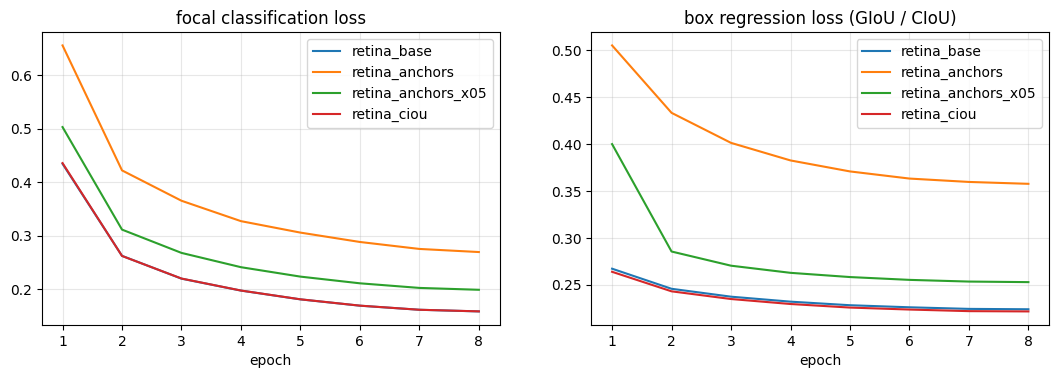

In [7]:
# --- Training loss per epoch ------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for name in RUNS:
    lp = U.find_run_file(name, "log.json")
    if lp:
        log = pd.DataFrame(json.load(open(lp)))
        ax[0].plot(log.epoch, log.classification, label=name)
        ax[1].plot(log.epoch, log.bbox_regression, label=name)
ax[0].set_title("focal classification loss"); ax[1].set_title("box regression loss (GIoU / CIoU)")
for a in ax:
    a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
plt.savefig(f"{WORK}/results/retina_losses.png", dpi=120, bbox_inches="tight"); plt.show()

## Removing the proposal stage

Without an RPN, every anchor is classified directly, so the classifier sees ~190 k candidates per frame of which only a few hundred are positive
(Faster R-CNN instead trains its head on 512 sampled RoIs with a fixed 25 % positive share). Three consequences:

1. **Extreme foreground/background imbalance.** The many easy background anchors dominate a plain cross-entropy loss. RetinaNet answers this with **focal loss** $FL(p_t) = -\alpha_t (1-p_t)^\gamma \log p_t$, which down-weights well-classified anchors, and with a prior-probability bias init (π = 0.01) so the head starts by predicting background.
2. **No second refinement.** Features are not re-pooled for each candidate box, so the box is predicted from the fixed receptive field at the anchor location; misaligned or tiny objects get one regression step instead of two. The box loss (GIoU/CIoU) and dense small anchors partly compensate.
3. **Assignment is fixed by anchor IoU.** Small objects overlap few anchors above the positive threshold, so they get few positive samples; this is why anchor shapes and IoU thresholds are the parameters tuned here (ATSS shows this assignment, not the anchor itself, explains most of the gap to anchor-free detectors).

## Comparison with Faster R-CNN and YOLOv8 (same holdout, same evaluator)

In [8]:
# --- Initial and tuned RetinaNet vs the tuned two-stage detector -----------------------------
# Faster R-CNN results are read from notebook 01's output (attach it as input)
others = {n: U.load_result(n) for n in ["frcnn_base", "frcnn_anchors", "frcnn_props", "frcnn_roi"]}
others = {n: m for n, m in others.items() if m}
if results:
    rows = {"retina_base (initial)": results.get("retina_base")}
    best_retina = max(results, key=lambda n: results[n]["mAP"])
    rows[f"{best_retina} (tuned)"] = results[best_retina]
    if others:
        best_frcnn = max(others, key=lambda n: others[n]["mAP"])
        rows[f"{best_frcnn} (tuned two-stage)"] = others[best_frcnn]
    cmp = pd.DataFrame({k: v for k, v in rows.items() if v}).T
    display(cmp[["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500", "FPS"]])

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,FPS
retina_base (initial),0.2259,0.4115,0.2139,0.0881,0.2007,0.4571,0.3568,4.8
retina_base (tuned),0.2259,0.4115,0.2139,0.0881,0.2007,0.4571,0.3568,4.8
frcnn_props (tuned two-stage),0.2401,0.4710,0.2191,0.1000,0.2120,0.4276,0.4246,4.7


## Test submission (best run)

In [9]:
# --- Predict the test set with the best RetinaNet run --------------------------------------
def make_submission(name):
    gc.collect(); torch.cuda.empty_cache()
    model = U.load_detector(KIND, RUNS[name], U.find_run_file(name, "model.pt"))
    test = pd.read_csv(os.path.join(U.comp_root(), "test_images.csv"))
    pred = {}
    for i, (image_id, rel) in enumerate(zip(test.image_id, test.file_name)):
        pred[image_id] = U.prediction_string(*U.detect(model, os.path.join(U.comp_root(), rel)))
        if i % 1000 == 0:
            print(f"{i}/{len(test)}")
    sub_path = f"{WORK}/submission_{name}.csv"
    sub = U.write_submission(pred, sub_path)
    with zipfile.ZipFile(sub_path[:-4] + ".zip", "w", zipfile.ZIP_DEFLATED) as z:
        z.write(sub_path, os.path.basename(sub_path))
    print(f"{name}: {len(sub)} rows, csv {os.path.getsize(sub_path) / 1e6:.0f} MB")

if results:
    try:
        make_submission(best_retina)
    except Exception:
        traceback.print_exc()

0/3811
1000/3811
2000/3811
3000/3811
retina_base: 3811 rows, csv 59 MB


## Conclusions

| run | change vs `retina_base` | mAP | AP50 | AP_small | AP_medium | AP_large | AR500 | public LB |
|---|---|---|---|---|---|---|---|---|
| `retina_base` | defaults (anchors 32–812 px, GIoU) | **0.226** | 0.412 | 0.088 | **0.201** | **0.457** | 0.357 | 0.1806 |
| `retina_anchors` | k-means anchors 9–112 px | 0.052 | 0.176 | 0.060 | 0.059 | 0.022 | 0.200 | – |
| `retina_anchors_x05` | default anchors × 0.5 | 0.197 | 0.409 | **0.097** | 0.184 | 0.373 | **0.395** | – |
| `retina_ciou` | GIoU → CIoU loss | 0.226 | **0.412** | 0.088 | 0.201 | 0.456 | 0.357 | – |

- **Search range and selection:** anchor configuration ∈ {default, k-means, default × 0.5}, box loss ∈ {GIoU, CIoU}; the tuned model is still `retina_base` (best holdout mAP), so the "initial" and "tuned" rows of the comparison table coincide.
- **k-means anchors failed because they ignore the grid.** k-means maximises IoU between box and anchor *shapes* at a shared centre (0.82 vs 0.60). On the real grid the anchor centres are a stride apart, and k-means put 40–112 px anchors on the stride-64/128 levels: only 28 % of 32–96 px boxes and 14 % of > 96 px boxes reach IoU 0.5 with any anchor (defaults: 100 %). These objects get no regular positives, which is why `AP_large` collapses to 0.02. Anchors have to be chosen per level, relative to the stride (YOLOv2's k-means works because its anchors are assigned to a single grid cell, not to FPN levels).
- **Smaller stride-aware anchors trade large objects for small ones.** Halving the defaults raises the share of boxes with a positive anchor from 75 % to 96 % (objects < 16 px: 0 % → 57 %), and `AP_small` (+0.009) and recall (+0.04) improve. But mAP drops by 0.03, mostly through `AP_large` (−0.08): many more positives on tiny objects dominate the focal loss, which is normalised by the number of positives, and the larger objects lose weight.
- **CIoU = GIoU here.** The extra centre-distance and aspect-ratio terms of CIoU matter when predicted and target boxes barely overlap. RetinaNet only regresses positive anchors, which already overlap their target with IoU ≥ 0.5, so both losses give almost the same gradient and the result is identical (±0.001).
- **One-stage vs two-stage.** Against the tuned Faster R-CNN (`frcnn_props`), RetinaNet is lower on mAP (0.226 vs 0.240), small objects (0.088 vs 0.100) and recall (0.357 vs 0.425) and better only on large objects (0.457 vs 0.428), at the same speed (5 FPS). Without proposals and RoI re-pooling, the dense head has one shot at each anchor, so tiny objects that fall between anchors are harder to recover. `bicycle` is almost never detected (AP 0.003): a rare class (4 %) of thin, low-contrast objects that the focal loss treats as hard background.